# 04 Distillation with a control
Goal: measure how much of the ensemble's gain a small student keeps, against a control. The teacher is the average of the tuned LightGBM and a random forest. The code that runs all seeds will live in `src/distill.py`.

## 1. Prediction (written before running anything)

**What is measured.** Each student is trained three ways: on true labels (the control, arm 1), on the teacher's out-of-fold labels for the same rows (arm 2), and on teacher labels for the real rows plus synthetic rows (arm 3). For a student and arm:

> share of the teacher's gain kept = (control RMSE − student RMSE) / (control RMSE − teacher RMSE)

0% means no better than the control, 100% means as good as the teacher, and a negative share means worse than the control.

**Expected shares** (test RMSE, mean over 5 seeds):

| Student | Arm 2: teacher labels, same rows | Arm 3: teacher labels + synthetic rows |
|---|---|---|
| MLP, 2 layers of 32 | about 10% | about 40% |
| MLP, 2 layers of 128 | about 15% | about 50% |
| Depth-limited tree | about 15% | about 35% |

**Why.**
- **Arm 2 helps only a little.** The student sees the same inputs as the control. The teacher's labels are smoother than the true ones, which removes some noise, but nothing new is learned about where the data lies.
- **Arm 3 helps most.** The synthetic rows give the student many more places to copy the teacher's function, and a function is easier to copy than noisy labels. This is where I expect the real gain.
- **The bigger MLP keeps more** because it has the capacity to use the extra rows. The small MLP runs out of capacity first.
- **The tree has the most to gain but the lowest ceiling.** Its control is the weakest, so the teacher's gain over it is large. But a depth-limited tree can only draw a blocky copy of the teacher, so it cannot keep most of that gain.

**What would surprise me.**
- Arm 2 beating arm 3.
- A negative share for any arm, meaning distillation hurt.
- The tree keeping more than either MLP.

A null result still counts. If distillation does not beat the control by more than the seed-to-seed noise, that is what gets reported.

## 2. Build the teacher
The teacher is the average of the tuned LightGBM (from `lightgbm_vs_mlp`) and a random forest of 300 trees, using the `max_features` that gave the best forest in `error_correlation`. `AverageEnsemble` in `src/lib.py` averages them, and can be saved with `joblib`. It is fit on the full training portion, and the test set is used here only to check it.

Note: this notebook trains LightGBM, so it must not load torch. That means no `set_seed` here (it imports torch). Every model below takes its seed directly.

In [1]:
import json

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

from src.lib import (
    RESULTS_DIR,
    AverageEnsemble,
    EarlyStoppingLGBM,
    evaluate_regression,
    load_data,
    load_split,
)
from src.utils import load_config

cfg = load_config()
seed = cfg["seed"]
X, y = load_data()
X, y = X.to_numpy(), y.to_numpy()
test_idx, folds = load_split()
dev_idx = np.sort(np.concatenate([val for _, val in folds]))  # the full training portion
X_dev, y_dev, X_test, y_test = X[dev_idx], y[dev_idx], X[test_idx], y[test_idx]

In [2]:
# Tuned LightGBM settings, and the best forest setting from the error-correlation sweep.
lgbm_params = json.loads((RESULTS_DIR / "best_lgbm.json").read_text())["params"]
sweep = pd.read_csv(RESULTS_DIR / "error_correlation_sweep.csv")
best_forest = sweep[sweep["bootstrap"]].sort_values("forest_rmse").iloc[0]
rf_max_features = int(best_forest["max_features"])
print("LightGBM:", lgbm_params)
print("random forest: 300 trees, max_features =", rf_max_features)

lgbm = EarlyStoppingLGBM(lgbm_params, seed=seed)
forest = RandomForestRegressor(
    n_estimators=300, max_features=rf_max_features, random_state=seed, n_jobs=-1
)
teacher = AverageEnsemble([lgbm, forest])

LightGBM: {'learning_rate': 0.053400495878730164, 'num_leaves': 104, 'n_estimators': 214, 'min_child_samples': 34, 'subsample': 0.7183586946161812, 'colsample_bytree': 0.6072923364097647, 'reg_lambda': 0.043064020633992874}
random forest: 300 trees, max_features = 4


In [3]:
models = {"LightGBM": lgbm, "Random forest": forest, "Teacher (average)": teacher}
rows = []
for name, model in models.items():
    model.fit(X_dev, y_dev)
    rows.append({"model": name, **evaluate_regression(y_test, model.predict(X_test))})

teacher_table = pd.DataFrame(rows).set_index("model")
teacher_table.round(4)

,rmse,mae,r2
model,,,
LightGBM,0.4413,0.2896,0.8514
Random forest,0.4941,0.3205,0.8137
Teacher (average),0.4578,0.2964,0.8400


In [4]:
# Why the average does not beat LightGBM: how similar are the two models' mistakes?
e_lgbm = lgbm.predict(X_test) - y_test
e_forest = forest.predict(X_test) - y_test
print("error correlation, LightGBM vs. forest:", round(np.corrcoef(e_lgbm, e_forest)[0, 1], 3))

error correlation, LightGBM vs. forest: 0.916


**Takeaways**
- **The teacher beats the random forest but not LightGBM.** Test RMSE is 0.458 for the teacher, 0.494 for the forest and 0.441 for LightGBM. The plan allows this if the reason is stated.
- **Why:** the two models make nearly the same mistakes (error correlation 0.92), so averaging removes very little error. This is the same result as the error-correlation experiment: high correlation means a small gain. And because the forest is the weaker model, the average lands between the two instead of below both.
- **Open decision:** the teacher stays as designed, an equal average, so the control-to-teacher gain in the next steps is measured against 0.458. Using LightGBM alone, or a weighted average chosen by CV on the training rows (not the test set), would give a stronger teacher.

## 3. Out-of-fold teacher labels
The teacher saw the true labels of the rows it trained on, so its predictions on those rows leak them, and a student trained on them would not be a clean test of distillation. Instead, for each of the 5 folds, train the teacher on the other 4 folds and predict the held-out fold. Together this gives a teacher prediction for every training row that the teacher never saw.

In [5]:
from src.lib import SPLIT_PATH, out_of_fold_predictions

oof = out_of_fold_predictions(teacher, X, y, folds)  # 5 teacher fits

labeled = ~np.isnan(oof)
assert labeled[dev_idx].all() and not labeled[test_idx].any()
print(f"{labeled.sum()} training rows have an out-of-fold teacher label; the {len(test_idx)} test rows have none")

16512 training rows have an out-of-fold teacher label; the 4128 test rows have none


In [6]:
# Out-of-fold labels are an honest estimate of the teacher. In-sample ones are too good.
oof_rmse = evaluate_regression(y_dev, oof[dev_idx])["rmse"]
in_sample_rmse = evaluate_regression(y_dev, teacher.predict(X_dev))["rmse"]
print(f"teacher RMSE vs. true labels on the training rows:")
print(f"  out-of-fold: {oof_rmse:.4f}")
print(f"  in-sample:   {in_sample_rmse:.4f}")

# Save for the distillation arms.
oof_path = SPLIT_PATH.parent / "teacher_oof.csv"
pd.DataFrame({"row": dev_idx, "teacher_oof": oof[dev_idx]}).to_csv(oof_path, index=False)

teacher RMSE vs. true labels on the training rows:
  out-of-fold: 0.4635
  in-sample:   0.2388


**Takeaways**
- **Every training row has a label the teacher never saw.** All 16,512 training rows have an out-of-fold teacher label, and the 4,128 test rows have none. They are saved to `data/teacher_oof.csv`.
- **In-sample labels would have leaked.** The teacher's error against the true labels is 0.464 out-of-fold but only 0.239 in-sample, about half. On its own training rows the teacher has partly memorized the answers, so a student trained on those labels would be learning the true labels in disguise and the control would be blurred.
- **0.464 is the honest accuracy of the teacher on training rows.** It is close to the teacher's test RMSE of 0.458.

## 4. Synthetic rows
One distillation arm adds extra rows that the teacher labels. Make them by resampling real training rows (with replacement) and adding a little noise to every feature, then clip to each feature's real min and max. Settings come from `configs/config.yaml`: about 5 times as many synthetic rows as real rows, with jitter of 5% of each feature's standard deviation. Latitude and longitude get less (2%), because jittering them independently can push a block into the ocean, where the teacher's labels would be extrapolation. The rows come from training rows only, never the test set.

In [7]:
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

from src.lib import make_synthetic_rows

feature_names = list(load_data()[0].columns)
dcfg = cfg["distill"]
noise_frac = np.array(
    [dcfg["latlon_noise_frac"] if c in ("Latitude", "Longitude") else dcfg["noise_frac"] for c in feature_names]
)
n_synth = dcfg["synthetic_ratio"] * len(X_dev)

X_synth = make_synthetic_rows(X_dev, n_synth, noise_frac, seed)
y_synth = teacher.predict(X_synth)  # labeled by the teacher fit on the full training portion
print(f"{len(X_synth)} synthetic rows ({dcfg['synthetic_ratio']}x the {len(X_dev)} real training rows)")
print("noise as a fraction of each feature's std:", dict(zip(feature_names, noise_frac)))

82560 synthetic rows (5x the 16512 real training rows)
noise as a fraction of each feature's std: {'MedInc': np.float64(0.05), 'HouseAge': np.float64(0.05), 'AveRooms': np.float64(0.05), 'AveBedrms': np.float64(0.05), 'Population': np.float64(0.05), 'AveOccup': np.float64(0.05), 'Latitude': np.float64(0.02), 'Longitude': np.float64(0.02)}


### Do the synthetic rows stay near real ones?
A scatter of latitude against longitude, and a number to go with it: how far is each synthetic row from the nearest real row, compared with how far apart real rows already are.

               real row to nearest other real row  \
p50 (degrees)                              0.0000   
p90 (degrees)                              0.0224   
p99 (degrees)                              0.1393   

               synthetic row to nearest real row  
p50 (degrees)                             0.0070  
p90 (degrees)                             0.0323  
p99 (degrees)                             0.0712  


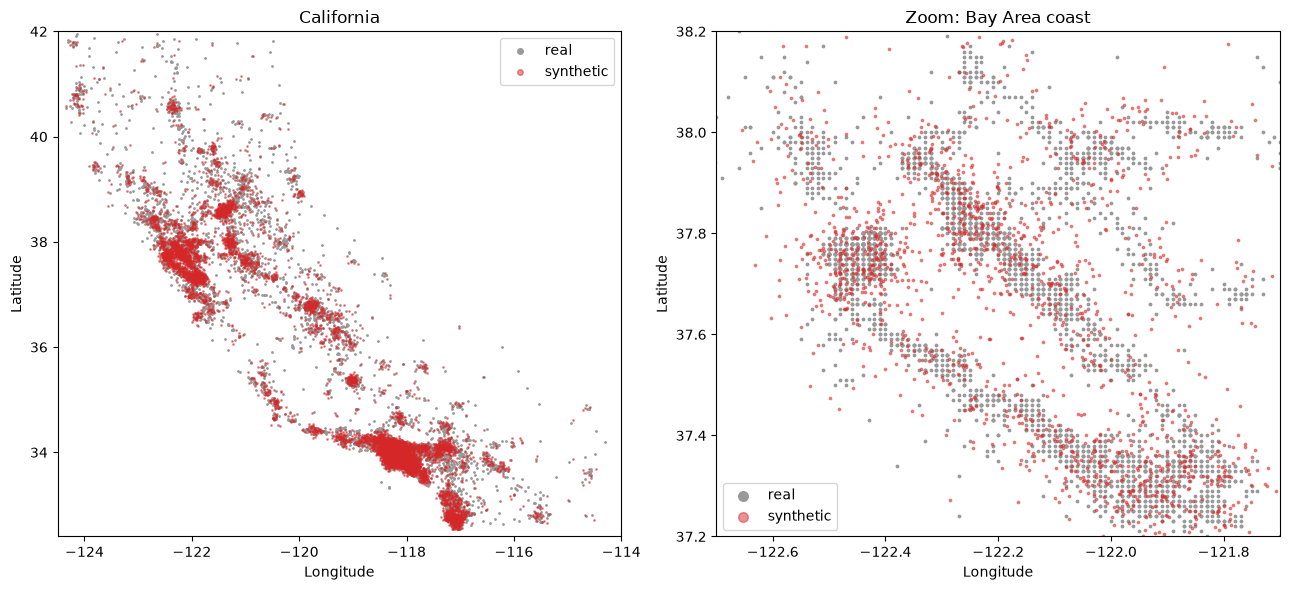

In [8]:
lat, lon = feature_names.index("Latitude"), feature_names.index("Longitude")
real_ll, synth_ll = X_dev[:, [lat, lon]], X_synth[:, [lat, lon]]
nn = NearestNeighbors(n_neighbors=2).fit(real_ll)
real_to_real = nn.kneighbors(real_ll)[0][:, 1]  # nearest OTHER real row
synth_to_real = nn.kneighbors(synth_ll, n_neighbors=1)[0][:, 0]
q = [50, 90, 99]
print(pd.DataFrame(
    {"real row to nearest other real row": np.percentile(real_to_real, q),
     "synthetic row to nearest real row": np.percentile(synth_to_real, q)},
    index=[f"p{k} (degrees)" for k in q],
).round(4))

show = np.random.default_rng(seed).choice(len(X_synth), 8000, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, (xlim, ylim, title) in zip(
    axes,
    [((-124.5, -114), (32.4, 42), "California"), ((-122.7, -121.7), (37.2, 38.2), "Zoom: Bay Area coast")],
):
    ax.scatter(real_ll[:, 1], real_ll[:, 0], s=3 if title != "California" else 1, c="0.6", label="real")
    ax.scatter(synth_ll[show, 1], synth_ll[show, 0], s=3 if title != "California" else 1, c="tab:red", alpha=0.5, label="synthetic")
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.legend(markerscale=4)
plt.tight_layout()
plt.show()

In [9]:
# The teacher's labels on the synthetic rows should look like real house values.
pd.DataFrame({"real labels": pd.Series(y_dev).describe(), "teacher labels, synthetic rows": pd.Series(y_synth).describe()}).round(3)

,real labels,"teacher labels, synthetic rows"
count,16512.000,82560.000
mean,2.072,2.112
std,1.156,1.030
min,0.150,0.429
25%,1.198,1.339
50%,1.798,1.898
75%,2.651,2.677
max,5.000,5.251


**Takeaways**
- **The synthetic rows stay near real ones.** The scatter follows California's shape, and in the zoom the red points sit on and between the real ones. A synthetic row is a median of 0.007 degrees from the nearest real row, and 99% are within 0.071 degrees. Real rows are 0.139 degrees from their nearest neighbor at the 99th percentile, so the synthetic rows are no more spread out than the data already is. A few points at the coast edge may sit just offshore.
- **The teacher's labels are smoother than the real ones.** On the synthetic rows they have mean 2.11 and std 1.03, against 2.07 and 1.16 for the real labels. That is expected: averaged models predict toward the middle.
- **One caveat:** the teacher labels go up to 5.25, above the $500k cap in the real data. This is left as is.

## 5. Define the students
Three small models: an MLP with 2 hidden layers of 32, an MLP with 2 of 128, and a single depth-limited tree (depth 6, the same tree as the baseline). Each is one object, built by `make_students` in `src/lib.py`, so scaling and target standardization are part of it: the MLPs are `TransformedTargetRegressor(Pipeline([scaler, MLPRegressor]), StandardScaler())`, and the tree needs neither. Settings are in `configs/config.yaml`; the MLP learning rate is near the tuned MLP's.

In [10]:
import time

from src.lib import make_students

students = make_students(cfg["distill"], seed)

# Smoke check: each student fits and predicts through one call. Fit on the first fold's training
# rows with true labels, score on that fold's held-out rows. Not the final control, and no test rows.
train_idx, val_idx = folds[0]
rows = []
for name, student in students.items():
    t0 = time.perf_counter()
    pred = student.fit(X[train_idx], y[train_idx]).predict(X[val_idx])
    rows.append(
        {
            "student": name,
            "val_rmse": evaluate_regression(y[val_idx], pred)["rmse"],
            "fit_seconds": time.perf_counter() - t0,
        }
    )
pd.DataFrame(rows).set_index("student").round(3)

,val_rmse,fit_seconds
student,,
MLP 2x32,0.550,0.540
MLP 2x128,0.527,1.004
Tree (depth 6),0.712,0.024


**Takeaways**
- **Each student fits and predicts through one call**, and predictions come back in units of $100k, so no extra scaling code is needed anywhere else.
- **Smoke check, trained on true labels (fold 0, not the final control):** validation RMSE is 0.527 for the MLP with 2 layers of 128, 0.550 for the one with 2 of 32, and 0.712 for the depth-6 tree. Fits take between 0.02 and 1 second.
- **The tree is the weakest control, the bigger MLP the strongest.** Against the teacher's out-of-fold RMSE of 0.464, the tree has the most headroom (about 0.25) and the MLPs far less (about 0.09 and 0.06). This is a rough comparison, since the student numbers come from one fold.